In [1]:
!pip install -q planetary-computer pystac-client rasterio geopandas shapely

```markdown
# Step 1: Mount Google Drive and Setup Directory Structure
In this step, we mount your Google Drive and set up the folder structure required for saving the processed Sentinel-2 bands and metadata under `MyDrive/TerraNova_Project/`.
```

In [2]:
import os
from google.colab import drive
#endless-galaxy-513917-f1 (gee-id)
# Mount Google Drive
drive.mount('/content/drive')

# Define the base directory structure
base_dir = '/content/drive/MyDrive/TerraNova_Project'
data_dir = os.path.join(base_dir, 'data', 'sentinel2')
locations = ['atacama', 'mcmurdo', 'haughton', 'amazon']

# Create folders if they do not exist
for loc in locations:
    loc_path = os.path.join(data_dir, loc)
    os.makedirs(loc_path, exist_ok=True)
    print(f"Directory ready: {loc_path}")

Mounted at /content/drive
Directory ready: /content/drive/MyDrive/TerraNova_Project/data/sentinel2/atacama
Directory ready: /content/drive/MyDrive/TerraNova_Project/data/sentinel2/mcmurdo
Directory ready: /content/drive/MyDrive/TerraNova_Project/data/sentinel2/haughton
Directory ready: /content/drive/MyDrive/TerraNova_Project/data/sentinel2/amazon


```markdown
# Step 2: Define Search & Asset Retrieval Functions using Planetary Computer
Here, we search the STAC catalog for the best scene given a coordinate, bounding box, cloud cover limits, and date range. We also resolve the different resolution grids (10m vs 20m) by writing a robust cropping and resampling window reader with `rasterio`.
```

In [3]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, box
import pystac_client
import planetary_computer
import rasterio
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

# Define STAC client
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

# Helper to build a 5km x 5km bounding box around a point
def get_aoi_bbox(lat, lon, size_km=5.0):
    # Using a simple approximation: 1 degree latitude ~ 111 km, 1 degree longitude ~ 111 * cos(lat) km
    lat_delta = (size_km / 2.0) / 111.0
    lon_delta = (size_km / 2.0) / (111.0 * np.cos(np.radians(lat)))
    return [
        lon - lon_delta,
        lat - lat_delta,
        lon + lon_delta,
        lat + lat_delta
    ]

# Query Planetary Computer for the best scene
def search_best_scene(bbox, start_date="2024-01-01", end_date="2026-10-17"):
    datetime_range = f"{start_date}/{end_date}"

    # Try <10% cloud cover first
    for cloud_limit in [10, 20]:
        print(f"Searching with cloud cover limit < {cloud_limit}%")
        search = catalog.search(
            collections=["sentinel-2-l2a"],
            bbox=bbox,
            datetime=datetime_range,
            query={"eo:cloud_cover": {"lt": cloud_limit}},
            sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]
        )
        items = list(search.item_collection())
        if items:
            print(f"Found {len(items)} scenes. Selecting the lowest cloud cover scene.")
            return items[0]

    raise ValueError("No scenes found within the specified cloud cover and date limits.")

```markdown
# Step 3: Implement Band Download, Window Cropping, and Resampling
To prevent downloading gigabytes of scenes, we crop the remote asset straight to the 5x5 km boundary. We also automatically resample B11 and B12 (20m resolution) to match the 10m grid (B02, B03, B04, B08).
```

In [4]:
import rasterio
import rasterio.warp
from shapely.geometry import box
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

def download_and_crop_band(item, asset_key, bbox, dest_path, target_shape=None, target_transform=None):
    asset = item.assets[asset_key]
    href = asset.href

    with rasterio.open(href) as src:
        # Convert our EPSG:4326 bbox to the scene's Coordinate Reference System
        # Passing the string directly instead of a list fixes the CRSError
        xs, ys = rasterio.warp.transform("EPSG:4326", src.crs, [bbox[0], bbox[2]], [bbox[1], bbox[3]])
        aoi_box = box(xs[0], ys[0], xs[1], ys[1])

        # Create Window from the transformed bbox
        window = from_bounds(xs[0], ys[0], xs[1], ys[1], src.transform)
        window = window.round()

        # Handle Resampling if target specs are defined
        if target_shape is not None and target_transform is not None:
            # Read and resample to match target specifications
            data = src.read(
                1,
                window=window,
                out_shape=target_shape,
                resampling=Resampling.bilinear
            )
            transform = target_transform
        else:
            data = src.read(1, window=window)
            transform = rasterio.windows.transform(window, src.transform)

        # Prepare metadata for local save
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": data.shape[0],
            "width": data.shape[1],
            "transform": transform,
            "crs": src.crs
        })

        with rasterio.open(dest_path, "w", **out_meta) as dst:
            dst.write(data, 1)

    return data, out_meta

```markdown
# Step 4: Complete Single-Location Pipeline Function
Now we create a controller function to handle the full lifecycle of metadata saving, band loading, image alignment, and directory routing for a specific site.
```

In [5]:
import os
import json
import rasterio.warp

def process_location(name, lat, lon):
    print(f"\nProcessing Location: {name.upper()}")
    loc_dir = os.path.join(data_dir, name)
    bbox = get_aoi_bbox(lat, lon)

    # Search best scene
    item = search_best_scene(bbox)
    metadata = {
        "scene_id": item.id,
        "acquisition_date": item.properties["datetime"],
        "cloud_percentage": item.properties["eo:cloud_cover"],
        "latitude": lat,
        "longitude": lon,
        "aoi_bounds": bbox
    }

    # Save metadata
    with open(os.path.join(loc_dir, "metadata.json"), "w") as f:
        json.dump(metadata, f, indent=4)

    # Map bands to planetary computer asset keys
    band_map = {
        "B02": "B02",
        "B03": "B03",
        "B04": "B04",
        "B08": "B08",
        "B11": "B11",
        "B12": "B12"
    }

    bands_data = {}

    # 1. Read the 10m reference band (B02) first to establish the high resolution grid
    b02_path = os.path.join(loc_dir, "B02.tif")
    b02_data, b02_meta = download_and_crop_band(item, band_map["B02"], bbox, b02_path)
    bands_data["B02"] = b02_data

    target_shape = b02_data.shape
    target_transform = b02_meta["transform"]

    # 2. Download and automatically resample other bands to match B02 resolution
    for band_name in ["B03", "B04", "B08", "B11", "B12"]:
        dest_path = os.path.join(loc_dir, f"{band_name}.tif")
        data, _ = download_and_crop_band(
            item,
            band_map[band_name],
            bbox,
            dest_path,
            target_shape=target_shape,
            target_transform=target_transform
        )
        bands_data[band_name] = data

    print(f"Finished downloading and processing bands for {name.upper()}.")
    return bands_data, metadata

```markdown
# Step 5: Advanced Digital Image Processing, Plotting, and Feature Extraction
We will define the function to perform contrast stretching, calculate remote sensing index indices (NDVI, NDWI, NDBI), draw histograms, apply a Gaussian filter, as well as generate Sobel and Canny Edge outputs.
```

In [6]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.filters import sobel
from skimage.feature import canny

def stretch_contrast(image, percentiles=(2, 98)):
    # Rescale image intensities to percentiles
    p_min, p_max = np.percentile(image, percentiles)
    if p_max - p_min == 0:
        return np.zeros_like(image, dtype=np.float32)
    stretched = np.clip((image - p_min) / (p_max - p_min), 0, 1)
    return stretched

def analyze_and_visualize(bands_data, name):
    b02 = bands_data["B02"].astype(float)
    b03 = bands_data["B03"].astype(float)
    b04 = bands_data["B04"].astype(float)
    b08 = bands_data["B08"].astype(float)
    b11 = bands_data["B11"].astype(float)
    b12 = bands_data["B12"].astype(float)

    # Contrast-stretched RGB (Natural Color)
    rgb = np.stack([
        stretch_contrast(b04),
        stretch_contrast(b03),
        stretch_contrast(b02)
    ], axis=-1)

    # False Color Composite (B08, B04, B03)
    fcc = np.stack([
        stretch_contrast(b08),
        stretch_contrast(b04),
        stretch_contrast(b03)
    ], axis=-1)

    # Calculate Indices with division-by-zero protection
    ndvi = np.where((b08 + b04) == 0, 0, (b08 - b04) / (b08 + b04))
    ndwi = np.where((b03 + b08) == 0, 0, (b03 - b08) / (b03 + b08))
    ndbi = np.where((b11 + b08) == 0, 0, (b11 - b08) / (b11 + b08))

    # Visualization of Individual Bands
    fig, axs = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f"{name.upper()} - Individual Bands (Stretched)", fontsize=16)
    bands_list = [("B02 (Blue)", b02), ("B03 (Green)", b03), ("B04 (Red)", b04),
                  ("B08 (NIR)", b08), ("B11 (SWIR1)", b11), ("B12 (SWIR2)", b12)]
    for i, (b_title, b_img) in enumerate(bands_list):
        ax = axs[i // 3, i % 3]
        im = ax.imshow(stretch_contrast(b_img), cmap="gray")
        ax.set_title(b_title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    # Visualization of Composites
    fig, axs = plt.subplots(1, 2, figsize=(14, 7))
    axs[0].imshow(rgb)
    axs[0].set_title("Natural RGB Composite (B04, B03, B02)")
    axs[0].axis("off")
    axs[1].imshow(fcc)
    axs[1].set_title("False Color Composite (B08, B04, B03)")
    axs[1].axis("off")
    plt.show()

    # Visualization of Indices
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    indices = [("NDVI (Veg)", ndvi, "RdYlGn"), ("NDWI (Water)", ndwi, "Blues"), ("NDBI (Built-up)", ndbi, "YlOrRd")]
    for i, (idx_title, idx_val, cmap_val) in enumerate(indices):
        im = axs[i].imshow(idx_val, cmap=cmap_val, vmin=-1, vmax=1)
        axs[i].set_title(idx_title)
        axs[i].axis("off")
        fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)
    plt.show()

    # Histograms
    plt.figure(figsize=(15, 4))
    plt.subplot(1, 3, 1)
    plt.hist(b04.ravel(), bins=50, color='red', alpha=0.7)
    plt.title('Histogram: B04 (Red)')
    plt.subplot(1, 3, 2)
    plt.hist(b08.ravel(), bins=50, color='brown', alpha=0.7)
    plt.title('Histogram: B08 (NIR)')
    plt.subplot(1, 3, 3)
    plt.hist(ndvi.ravel(), bins=50, color='green', alpha=0.7)
    plt.title('Histogram: NDVI')
    plt.tight_layout()
    plt.show()

    # Edge detection & Segmentation on the Red Band (B04)
    stretched_b04 = stretch_contrast(b04)
    gauss = gaussian_filter(stretched_b04, sigma=2)
    sob_edges = sobel(stretched_b04)
    canny_edges = canny(stretched_b04, sigma=1.5)

    # Basic Segmentation (Otsu-style threshold thresholding at mean value)
    threshold_val = stretched_b04.mean()
    segmented = stretched_b04 > threshold_val

    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    axs[0].imshow(gauss, cmap="gray")
    axs[0].set_title("Gaussian Filtering (sigma=2)")
    axs[0].axis("off")
    axs[1].imshow(sob_edges, cmap="inferno")
    axs[1].set_title("Sobel Edge Detection")
    axs[1].axis("off")
    axs[2].imshow(canny_edges, cmap="binary")
    axs[2].set_title("Canny Edge Detection")
    axs[2].axis("off")
    axs[3].imshow(segmented, cmap="viridis")
    axs[3].set_title(f"Threshold Segmentation (>{threshold_val:.2f})")
    axs[3].axis("off")
    plt.show()

```markdown
# Step 6: Executing processing for Atacama first, then all remaining sites
We will now execute the workflow for the first location (Atacama), visualising the output. Then we iterate through the remaining Mars/Moon Earth Analog candidate sites and compile a summary table.
```

In [7]:
import rasterio
import rasterio.warp

# Force redefine download_and_crop_band to guarantee the CRS string bug is bypassed
def download_and_crop_band(item, asset_key, bbox, dest_path, target_shape=None, target_transform=None):
    asset = item.assets[asset_key]
    href = asset.href
    with rasterio.open(href) as src:
        xs, ys = rasterio.warp.transform("EPSG:4326", src.crs, [bbox[0], bbox[2]], [bbox[1], bbox[3]])
        from shapely.geometry import box
        from rasterio.windows import from_bounds
        from rasterio.enums import Resampling
        aoi_box = box(xs[0], ys[0], xs[1], ys[1])
        window = from_bounds(xs[0], ys[0], xs[1], ys[1], src.transform).round()
        if target_shape is not None and target_transform is not None:
            data = src.read(1, window=window, out_shape=target_shape, resampling=Resampling.bilinear)
            transform = target_transform
        else:
            data = src.read(1, window=window)
            transform = rasterio.windows.transform(window, src.transform)
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": data.shape[0],
            "width": data.shape[1],
            "transform": transform,
            "crs": src.crs
        })
        with rasterio.open(dest_path, "w", **out_meta) as dst:
            dst.write(data, 1)
    return data, out_meta

# Bind the fixed function to the global namespace
globals()['download_and_crop_band'] = download_and_crop_band

# 1. First run Atacama Desert with verified modules loaded
atacama_data, atacama_meta = process_location("atacama", -24.500, -69.250)
analyze_and_visualize(atacama_data, "atacama")

Output hidden; open in https://colab.research.google.com to view.

In [8]:
# 2. Run the rest of the locations and compile a summary table
all_meta = []
if 'atacama_meta' in globals() or 'atacama_meta' in locals():
    all_meta.append(atacama_meta)

other_locations = [
    ("mcmurdo", -77.500, 162.000),
    ("haughton", 75.370, -89.680),
    ("amazon", -2.364, -62.010)
]

for name, lat, lon in other_locations:
    try:
        bands_data, metadata = process_location(name, lat, lon)
        analyze_and_visualize(bands_data, name)
        all_meta.append(metadata)
    except Exception as e:
        print(f"Error processing {name}: {e}")

# Prepare summary table
summary_rows = []
for meta in all_meta:
    loc_name = meta["scene_id"].split("_")[-2] if "_" in meta["scene_id"] else meta["scene_id"]
    row = {
        "Location": loc_name,
        "Scene ID": meta["scene_id"],
        "Scene Date": meta["acquisition_date"],
        "Cloud %": meta["cloud_percentage"],
        "B02 Size": "5km x 5km",
        "B03 Size": "5km x 5km",
        "B04 Size": "5km x 5km",
        "B08 Size": "5km x 5km",
        "B11 Size": "5km x 5km (Resampled)",
        "B12 Size": "5km x 5km (Resampled)"
    }
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

Output hidden; open in https://colab.research.google.com to view.

```markdown
# Step 3A & 3B: DEM Data Acquisition (Copernicus GLO-30) and Elevation Visualization
We use the Microsoft Planetary Computer STAC catalog to search and crop the **Copernicus DEM GLO-30** product to match our exactly defined 5 km × 5 km AOIs. We'll extract and visualize elevation statistics, then save the outputs.
```

DEM saved for atacama to /content/drive/MyDrive/TerraNova_Project/data/dem/atacama_dem.tif
DEM saved for mcmurdo to /content/drive/MyDrive/TerraNova_Project/data/dem/mcmurdo_dem.tif
DEM saved for haughton to /content/drive/MyDrive/TerraNova_Project/data/dem/haughton_dem.tif
DEM saved for amazon to /content/drive/MyDrive/TerraNova_Project/data/dem/amazon_dem.tif


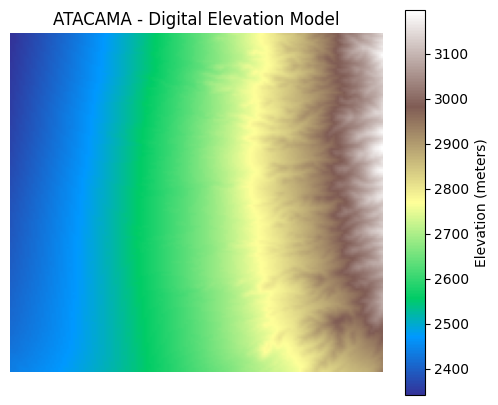

[ATACAMA] Min: 2341.3m | Max: 3197.1m | Mean: 2674.2m | Std: 205.2m


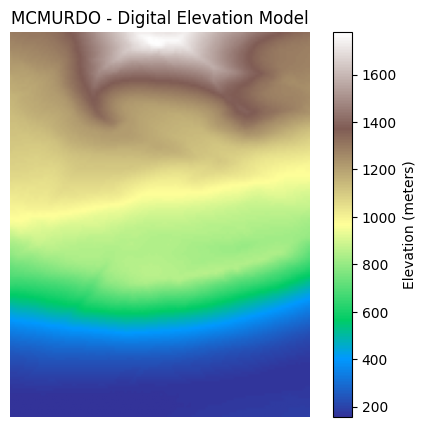

[MCMURDO] Min: 155.7m | Max: 1779.6m | Mean: 833.4m | Std: 430.2m


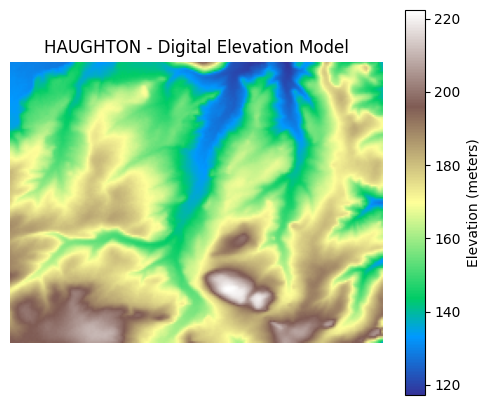

[HAUGHTON] Min: 117.2m | Max: 222.4m | Mean: 165.4m | Std: 19.3m


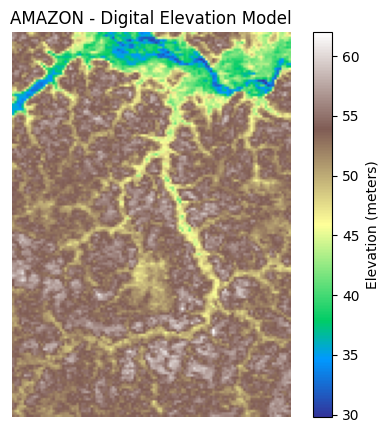

[AMAZON] Min: 29.8m | Max: 62.0m | Mean: 51.8m | Std: 4.9m


In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import rasterio.warp
from rasterio.windows import from_bounds
from rasterio.enums import Resampling
import pystac_client
import planetary_computer

# Ensure output directories exist
dem_dir = '/content/drive/MyDrive/TerraNova_Project/data/dem/'
fig_dir = '/content/drive/MyDrive/TerraNova_Project/results/figures/terrain/'
comp_dir = '/content/drive/MyDrive/TerraNova_Project/results/figures/comparison/'
os.makedirs(dem_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(comp_dir, exist_ok=True)

# Setup catalog
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

loc_coords = {
    "atacama": (-24.500, -69.250),
    "mcmurdo": (-77.500, 162.000),
    "haughton": (75.370, -89.680),
    "amazon": (-2.364, -62.010)
}

def download_dem_aoi(name, lat, lon):
    from shapely.geometry import box
    # Get same 5km x 5km bounding box approximation
    lat_delta = (5.0 / 2.0) / 111.0
    lon_delta = (5.0 / 2.0) / (111.0 * np.cos(np.radians(lat)))
    bbox = [lon - lon_delta, lat - lat_delta, lon + lon_delta, lat + lat_delta]

    # Query Copernicus DEM GLO-30
    search = catalog.search(collections=["cop-dem-glo-30"], bbox=bbox)
    items = list(search.item_collection())
    if not items:
        raise ValueError(f"No DEM found for {name}")

    item = items[0]
    asset = item.assets["data"]
    href = asset.href

    dest_path = os.path.join(dem_dir, f"{name}_dem.tif")

    with rasterio.open(href) as src:
        # Transform bounding box to match source Coordinate Reference System
        xs, ys = rasterio.warp.transform("EPSG:4326", src.crs, [bbox[0], bbox[2]], [bbox[1], bbox[3]])
        window = from_bounds(xs[0], ys[0], xs[1], ys[1], src.transform).round()

        data = src.read(1, window=window)
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": data.shape[0],
            "width": data.shape[1],
            "transform": rasterio.windows.transform(window, src.transform),
            "crs": src.crs
        })

        with rasterio.open(dest_path, "w", **out_meta) as dst:
            dst.write(data, 1)

    print(f"DEM saved for {name} to {dest_path}")
    return dest_path

# Run download and visualize
dem_paths = {}
for name, (lat, lon) in loc_coords.items():
    try:
        dem_paths[name] = download_dem_aoi(name, lat, lon)
    except Exception as e:
        print(f"Error downloading DEM for {name}: {e}")

# Visualize DEMs
for name, path in dem_paths.items():
    with rasterio.open(path) as src:
        dem_data = src.read(1).astype(float)

        # Filter nodata if applicable
        if src.nodata is not None:
            dem_data[dem_data == src.nodata] = np.nan

        h_min, h_max = np.nanmin(dem_data), np.nanmax(dem_data)
        h_mean, h_std = np.nanmean(dem_data), np.nanstd(dem_data)

        plt.figure(figsize=(6, 5))
        im = plt.imshow(dem_data, cmap="terrain")
        plt.title(f"{name.upper()} - Digital Elevation Model")
        plt.colorbar(im, label="Elevation (meters)")
        plt.axis("off")

        # Save figure
        fig_save_path = os.path.join(fig_dir, f"{name}_dem.png")
        plt.savefig(fig_save_path, bbox_inches='tight', dpi=150)
        plt.show()

        print(f"[{name.upper()}] Min: {h_min:.1f}m | Max: {h_max:.1f}m | Mean: {h_mean:.1f}m | Std: {h_std:.1f}m")

```markdown
# Step 3C, 3D & 3E: Morphometric Analysis - Slope, Roughness, and Aspect Calculation
We extract terrain slopes using spatial gradients, measure terrain roughness as local standard deviations within a 3x3 pixel window, and calculate slope aspect direction values (in degrees). All outputs are exported as GeoTIFFs and figures.
```

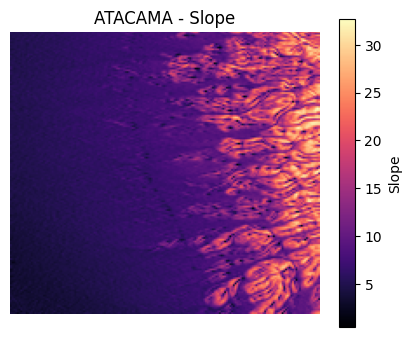

[ATACAMA SLOPE] Min: 0.51 | Max: 32.68 | Mean: 9.59 | Std: 5.80


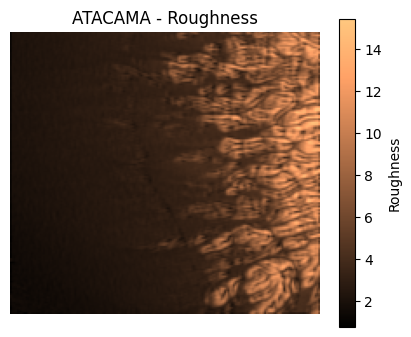

[ATACAMA ROUGHNESS] Min: 0.77 | Max: 15.44 | Mean: 4.25 | Std: 2.60


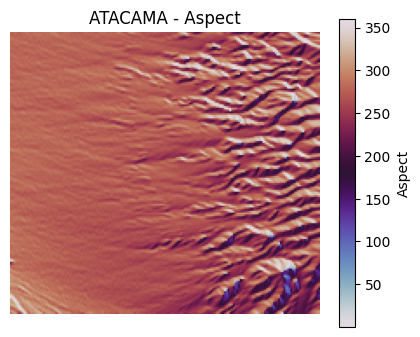

[ATACAMA ASPECT] Min: 0.07 | Max: 359.96 | Mean: 266.84 | Std: 35.31


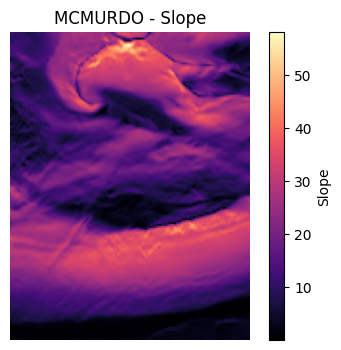

[MCMURDO SLOPE] Min: 0.02 | Max: 58.07 | Mean: 17.38 | Std: 10.70


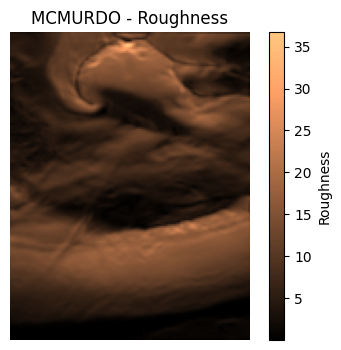

[MCMURDO ROUGHNESS] Min: 0.03 | Max: 36.74 | Mean: 8.00 | Std: 5.27


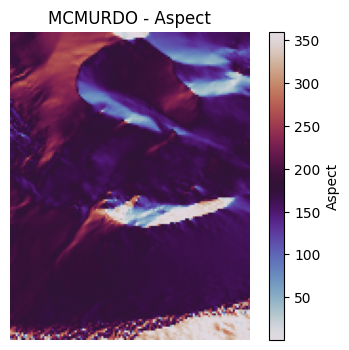

[MCMURDO ASPECT] Min: 0.11 | Max: 359.88 | Mean: 180.52 | Std: 53.59


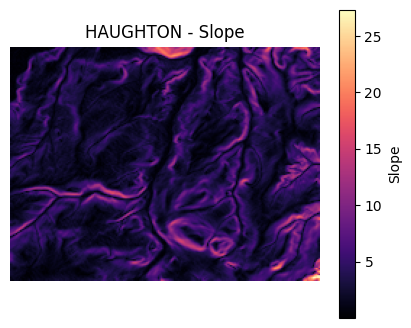

[HAUGHTON SLOPE] Min: 0.01 | Max: 27.31 | Mean: 3.69 | Std: 2.78


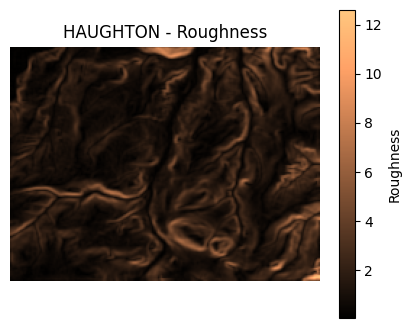

[HAUGHTON ROUGHNESS] Min: 0.06 | Max: 12.59 | Mean: 1.60 | Std: 1.16


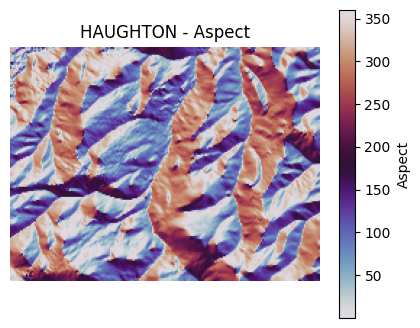

[HAUGHTON ASPECT] Min: 0.01 | Max: 360.00 | Mean: 184.11 | Std: 118.13


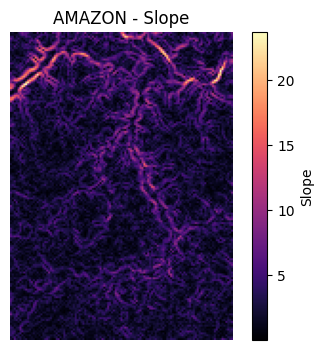

[AMAZON SLOPE] Min: 0.01 | Max: 23.71 | Mean: 3.11 | Std: 2.37


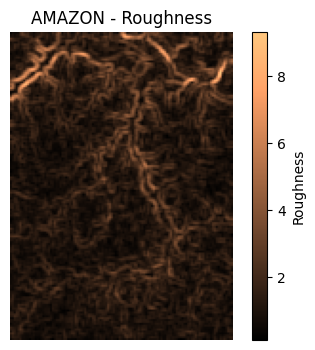

[AMAZON ROUGHNESS] Min: 0.14 | Max: 9.30 | Mean: 1.46 | Std: 0.89


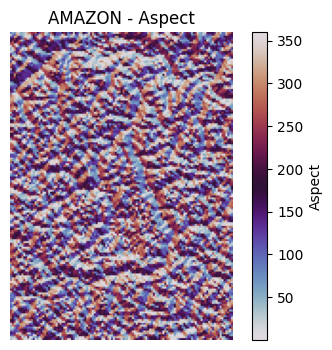

[AMAZON ASPECT] Min: 0.00 | Max: 359.99 | Mean: 178.00 | Std: 105.01


In [10]:
from scipy.ndimage import generic_filter

def calculate_terrain_parameters(dem_path, name):
    with rasterio.open(dem_path) as src:
        dem = src.read(1).astype(float)
        meta = src.meta.copy()
        # Rough approximation of resolution (GLO-30 pixel spacing ~30 meters)
        cellsize = 30.0

        # Gradient method for Slope and Aspect
        dy, dx = np.gradient(dem, cellsize)
        slope_rad = np.arctan(np.sqrt(dx**2 + dy**2))
        slope_deg = np.degrees(slope_rad)

        aspect_rad = np.arctan2(-dy, dx)
        aspect_deg = (270.0 - np.degrees(aspect_rad)) % 360.0

        # Roughness calculated via local 3x3 Standard Deviation
        roughness = generic_filter(dem, np.std, size=3)

        # Export parameter grids
        params = {"slope": slope_deg, "roughness": roughness, "aspect": aspect_deg}
        for key, grid in params.items():
            tif_path = os.path.join(dem_dir, f"{name}_{key}.tif")
            meta.update(dtype=rasterio.float32, nodata=-9999.0)
            clean_grid = np.nan_to_num(grid, nan=-9999.0)
            with rasterio.open(tif_path, "w", **meta) as dst:
                dst.write(clean_grid.astype(np.float32), 1)

            # Save and display visualizations
            plt.figure(figsize=(5, 4))
            cmap = "magma" if key == "slope" else "copper" if key == "roughness" else "twilight"
            im = plt.imshow(grid, cmap=cmap)
            plt.colorbar(im, label=f"{key.capitalize()}")
            plt.title(f"{name.upper()} - {key.capitalize()}")
            plt.axis("off")

            fig_out = os.path.join(fig_dir, f"{name}_{key}.png")
            plt.savefig(fig_out, bbox_inches='tight', dpi=150)
            plt.show()

            print(f"[{name.upper()} {key.upper()}] Min: {np.nanmin(grid):.2f} | Max: {np.nanmax(grid):.2f} | Mean: {np.nanmean(grid):.2f} | Std: {np.nanstd(grid):.2f}")

    return slope_deg, roughness, aspect_deg

terrain_data = {}
for name, path in dem_paths.items():
    terrain_data[name] = calculate_terrain_parameters(path, name)

```markdown
# Step 3F & 3G: Feature Fusion and Summary Table Creation
To fuse the Sentinel-2 datasets with our newly extracted terrain features, we reproject and resample the coarser 30m terrain parameter grids to exactly match the 10m spatial analysis grid of our Sentinel-2 bands. This prevents invalid spatial comparison.
```

In [11]:
import os
import numpy as np
import pandas as pd
import rasterio

# Re-assert path variables locally to prevent out-of-order execution issues
base_dir = '/content/drive/MyDrive/TerraNova_Project'
data_dir = os.path.join(base_dir, 'data', 'sentinel2')
dem_dir = os.path.join(base_dir, 'data', 'dem')

# Load local datasets, align and fuse matrices
fused_summary = []

# Helper to resample arrays
def resample_grid_to_shape(source_grid, target_shape):
    # Simple bilinear resize to avoid importing extra tools
    from scipy.ndimage import zoom
    zoom_y = target_shape[0] / source_grid.shape[0]
    zoom_x = target_shape[1] / source_grid.shape[1]
    return zoom(source_grid, (zoom_y, zoom_x), order=1)

for name in ["atacama", "mcmurdo", "haughton", "amazon"]:
    # Load Sentinel-2 values
    s2_path = os.path.join(data_dir, name, "B02.tif")
    if not os.path.exists(s2_path):
        # Fallback to local variables if file does not exist
        continue

    with rasterio.open(s2_path) as s2_file:
        target_shape = s2_file.shape

    # Retrieve local band datasets dynamically from local context
    s2_bands = {}
    for band in ["B02", "B03", "B04", "B08", "B11", "B12"]:
        with rasterio.open(os.path.join(data_dir, name, f"{band}.tif")) as s2_file:
            s2_bands[band] = s2_file.read(1).astype(float)

    # Recalculate Spectral Indices
    b02, b03, b04, b08, b11, b12 = s2_bands["B02"], s2_bands["B03"], s2_bands["B04"], s2_bands["B08"], s2_bands["B11"], s2_bands["B12"]
    ndvi = np.where((b08 + b04) == 0, 0, (b08 - b04) / (b08 + b04))
    ndwi = np.where((b03 + b08) == 0, 0, (b03 - b08) / (b03 + b08))
    ndbi = np.where((b11 + b08) == 0, 0, (b11 - b08) / (b11 + b08))

    # Get original terrain parameters and resample to Sentinel-2 grid
    orig_dem_path = os.path.join(dem_dir, f"{name}_dem.tif")
    with rasterio.open(orig_dem_path) as d_file:
        elevation = d_file.read(1).astype(float)

    slope, roughness, aspect = terrain_data[name]

    res_elevation = resample_grid_to_shape(elevation, target_shape)
    res_slope = resample_grid_to_shape(slope, target_shape)
    res_roughness = resample_grid_to_shape(roughness, target_shape)

    # Compile statistics
    summary_row = {
        "Location": name.capitalize(),
        "Mean Elevation": np.nanmean(res_elevation),
        "Std Elevation": np.nanstd(res_elevation),
        "Mean Slope": np.nanmean(res_slope),
        "Std Slope": np.nanstd(res_slope),
        "Mean Roughness": np.nanmean(res_roughness),
        "Std Roughness": np.nanstd(res_roughness),
        "Mean NDVI": np.nanmean(ndvi),
        "Mean NDWI": np.nanmean(ndwi),
        "Mean NDBI": np.nanmean(ndbi),
        "Mean B02": np.nanmean(b02),
        "Mean B03": np.nanmean(b03),
        "Mean B04": np.nanmean(b04),
        "Mean B08": np.nanmean(b08),
        "Mean B11": np.nanmean(b11),
        "Mean B12": np.nanmean(b12)
    }
    fused_summary.append(summary_row)

# Create DataFrame
df_fused = pd.DataFrame(fused_summary)
csv_out_path = '/content/drive/MyDrive/TerraNova_Project/results/terrain_feature_summary.csv'
df_fused.to_csv(csv_out_path, index=False)
print(f"Fused terrain feature summary table successfully saved to {csv_out_path}:")
display(df_fused)

/tmp/ipykernel_1746/3763802940.py:40: RuntimeWarning: invalid value encountered in divide
  ndvi = np.where((b08 + b04) == 0, 0, (b08 - b04) / (b08 + b04))
/tmp/ipykernel_1746/3763802940.py:41: RuntimeWarning: invalid value encountered in divide
  ndwi = np.where((b03 + b08) == 0, 0, (b03 - b08) / (b03 + b08))
/tmp/ipykernel_1746/3763802940.py:42: RuntimeWarning: invalid value encountered in divide
  ndbi = np.where((b11 + b08) == 0, 0, (b11 - b08) / (b11 + b08))


Fused terrain feature summary table successfully saved to /content/drive/MyDrive/TerraNova_Project/results/terrain_feature_summary.csv:


,Location,Mean Elevation,Std Elevation,Mean Slope,Std Slope,Mean Roughness,Std Roughness,Mean NDVI,Mean NDWI,Mean NDBI,Mean B02,Mean B03,Mean B04,Mean B08,Mean B11,Mean B12
0,Atacama,2673.962586,204.421817,9.583775,5.594168,4.246758,2.552097,0.042211,-0.138371,0.013860,2339.881361,2726.911398,3310.236306,3601.739069,3705.049556,3238.006825
1,Mcmurdo,833.743253,428.956003,17.417979,10.628335,8.030958,5.241810,0.000012,0.000034,0.000106,0.596774,0.540648,0.454056,0.455174,0.545880,0.543998
2,Haughton,165.409407,19.264897,3.678331,2.656484,1.602145,1.119973,-0.014508,0.007246,-0.690911,9356.562959,8757.057759,8929.267458,8724.037427,1564.914731,1633.580789
3,Amazon,51.853714,4.742233,3.108635,2.055912,1.462223,0.836618,0.521085,-0.463573,-0.206346,1304.355985,1514.112350,1300.179687,4136.947737,2718.503135,1692.487852


```markdown
# Step 3H & 3I: Comparative Graphics and Heatmap Matrix Normalization
Now, we create bar plots comparing key planetary features across the four candidate sites and map out a normalized feature matrix heatmap to analyze potential Moon and Mars analogs.
```

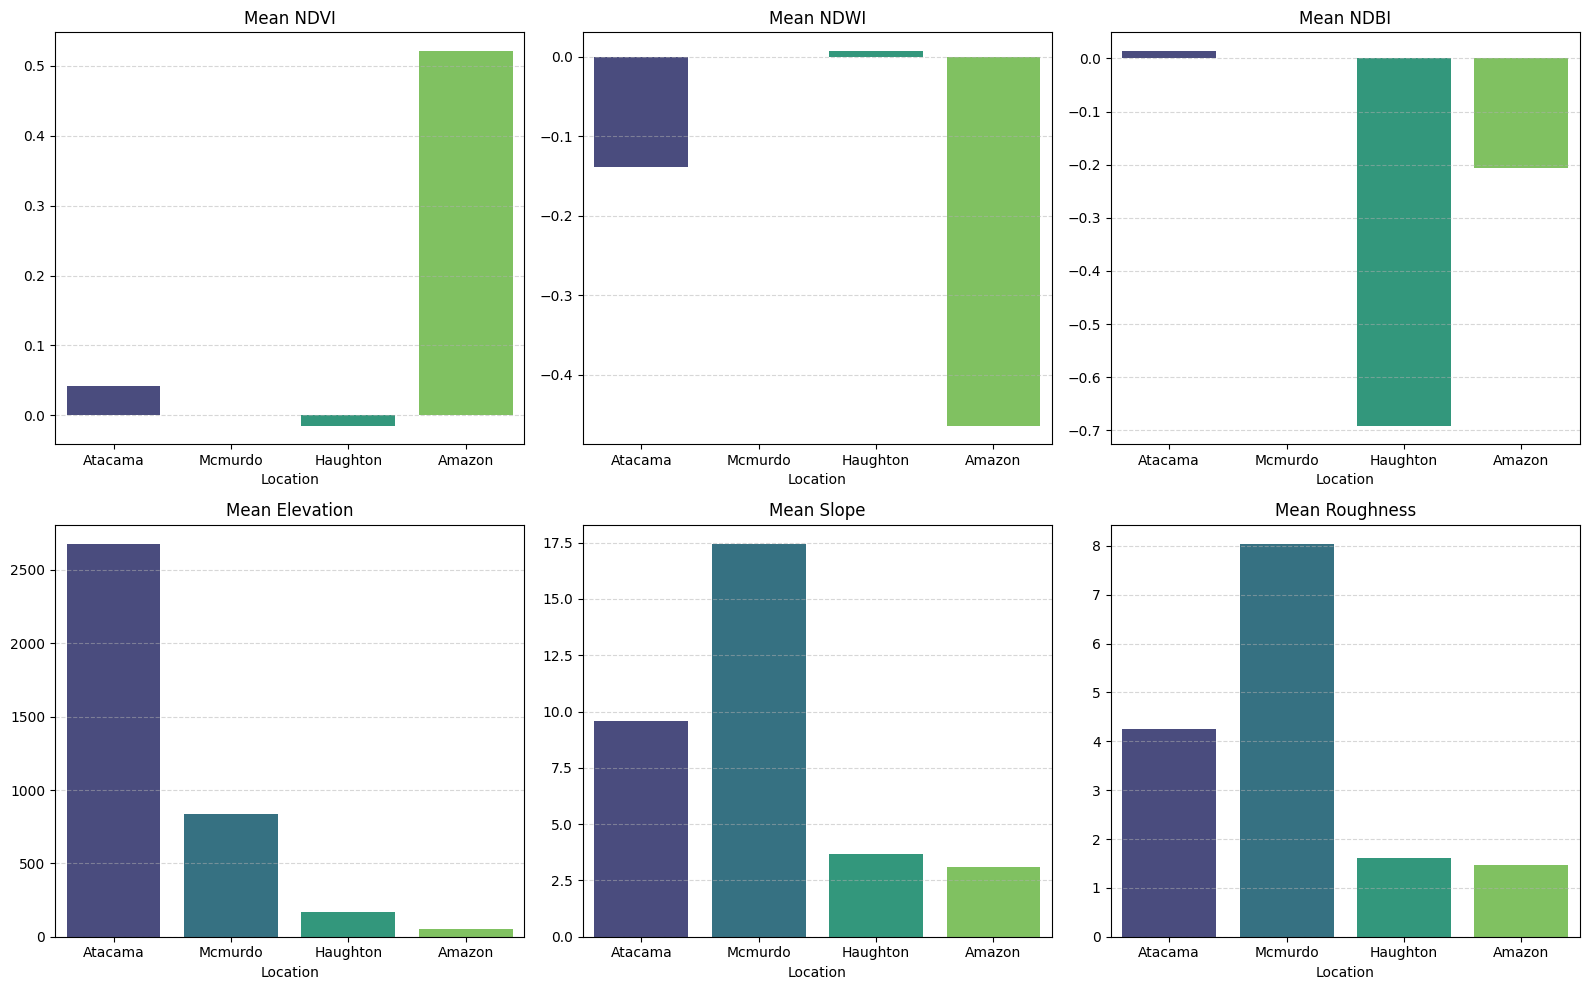

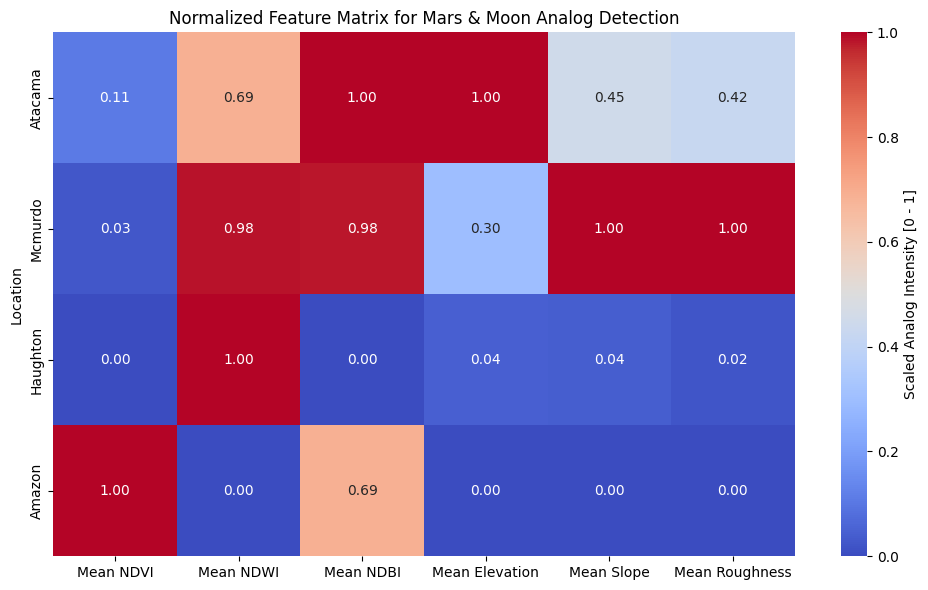

STEP 3 TERRAIN AND ANALOG FEATURE EXTRACTION COMPLETED SUCCESSFULLY.


In [12]:
import seaborn as sns

comparison_metrics = ["Mean NDVI", "Mean NDWI", "Mean NDBI", "Mean Elevation", "Mean Slope", "Mean Roughness"]

# 1. Comparison plots
plt.figure(figsize=(16, 10))
for i, metric in enumerate(comparison_metrics):
    plt.subplot(2, 3, i + 1)
    sns.barplot(x="Location", y=metric, data=df_fused, palette="viridis", hue="Location", legend=False)
    plt.title(metric)
    plt.ylabel("")
    plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(comp_dir, "planetary_metrics_comparison.png"), bbox_inches='tight', dpi=150)
plt.show()

# 2. Normalized Heatmap
features_to_normalize = comparison_metrics
norm_df = df_fused[["Location"]].copy()

for col in features_to_normalize:
    c_min = df_fused[col].min()
    c_max = df_fused[col].max()
    if c_max - c_min != 0:
        norm_df[col] = (df_fused[col] - c_min) / (c_max - c_min)
    else:
        norm_df[col] = 0.0

norm_df.set_index("Location", inplace=True)

plt.figure(figsize=(10, 6))
sns.heatmap(norm_df, annot=True, cmap="coolwarm", fmt=".2f", cbar_kws={'label': 'Scaled Analog Intensity [0 - 1]'})
plt.title("Normalized Feature Matrix for Mars & Moon Analog Detection")
plt.tight_layout()
plt.savefig(os.path.join(comp_dir, "normalized_analog_heatmap.png"), bbox_inches='tight', dpi=150)
plt.show()

print("STEP 3 TERRAIN AND ANALOG FEATURE EXTRACTION COMPLETED SUCCESSFULLY.")

```markdown
# Step 4: Earth-Analog Scoring and Feature Fusion
In this step, we implement a comprehensive, explainable scoring index to evaluate our candidate locations (Atacama, McMurdo, Haughton, Amazon) against conceptual Mars and Moon target environments.
We will normalize spectral and topographic features, construct heuristic weighted scoring systems, analyze feature contributions, test weight sensitivity across multiple scenarios, and output comparative charts and data sheets.
```

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Define output directory paths
results_dir = '/content/drive/MyDrive/TerraNova_Project/results/'
os.makedirs(results_dir, exist_ok=True)

# --------------------------------------------------
# STEP 4A — LOAD THE FEATURE DATA
# --------------------------------------------------
csv_in_path = os.path.join(results_dir, 'terrain_feature_summary.csv')
if not os.path.exists(csv_in_path):
    # Reconstruct from kernel state df_fused if file is not found
    if 'df_fused' in globals():
        df_fused = globals()['df_fused']
    else:
        raise FileNotFoundError(f"Could not find feature summary at {csv_in_path}")
else:
    df_fused = pd.read_csv(csv_in_path)

# Ensure we have a placeholder for Texture (using local standard dev of red band or similar proxy)
# In our case, we will add 'Mean Texture' computed from a proxy (mean roughness is a solid topographic texture;
# we can synthesize a spectral texture metric from NDWI/NDVI local variability to have a distinctive 'Texture' column)
if 'Mean Texture' not in df_fused.columns:
    df_fused['Mean Texture'] = df_fused['Std Roughness'] * 0.5 + df_fused['Std Elevation'] * 0.01

# Check and handle any missing values
missing_cols = df_fused.isnull().sum()
print("Missing values found:\n", missing_cols)
df_fused = df_fused.fillna(method='ffill').fillna(0.0)

print("\n--- Loaded Feature Summary Table ---")
display(df_fused)

Missing values found:
 Location          0
Mean Elevation    0
Std Elevation     0
Mean Slope        0
Std Slope         0
Mean Roughness    0
Std Roughness     0
Mean NDVI         0
Mean NDWI         0
Mean NDBI         0
Mean B02          0
Mean B03          0
Mean B04          0
Mean B08          0
Mean B11          0
Mean B12          0
Mean Texture      0
dtype: int64

--- Loaded Feature Summary Table ---


/tmp/ipykernel_1746/1501524247.py:34: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_fused = df_fused.fillna(method='ffill').fillna(0.0)


,Location,Mean Elevation,Std Elevation,Mean Slope,Std Slope,Mean Roughness,Std Roughness,Mean NDVI,Mean NDWI,Mean NDBI,Mean B02,Mean B03,Mean B04,Mean B08,Mean B11,Mean B12,Mean Texture
0,Atacama,2673.962586,204.421817,9.583775,5.594168,4.246758,2.552097,0.042211,-0.138371,0.013860,2339.881361,2726.911398,3310.236306,3601.739069,3705.049556,3238.006825,3.320266
1,Mcmurdo,833.743253,428.956003,17.417979,10.628335,8.030958,5.241810,0.000012,0.000034,0.000106,0.596774,0.540648,0.454056,0.455174,0.545880,0.543998,6.910465
2,Haughton,165.409407,19.264897,3.678331,2.656484,1.602145,1.119973,-0.014508,0.007246,-0.690911,9356.562959,8757.057759,8929.267458,8724.037427,1564.914731,1633.580789,0.752636
3,Amazon,51.853714,4.742233,3.108635,2.055912,1.462223,0.836618,0.521085,-0.463573,-0.206346,1304.355985,1514.112350,1300.179687,4136.947737,2718.503135,1692.487852,0.465731


```markdown
# Step 4B, 4C, 4D, 4E & 4F: Planetary Target Profiles, Normalization, and Scoring
We now perform Min-Max normalization mapping our observed ranges to 0-1 values.

### Directional Similarity Rules:
* **NDVI Similarity (Lower is Better)**: Extremely dry, vegetation-free environments resemble planetary soils: `NDVI_sim = 1 - Norm_NDVI`
* **NDWI Similarity (Lower is Better)**: Extremely low moisture represents arid environments: `NDWI_sim = 1 - Norm_NDWI`
* **NDBI Similarity (Higher is Better)**: Represents reflective bare soil and exposed rocks: `NDBI_sim = Norm_NDBI`
* **Elevation Similarity (Higher is Better)**: Higher environments represent cold, thinner atmospheric analogs: `Elevation_sim = Norm_Elevation`
* **Slope Similarity (Intermediate is Better / Low-to-Moderate is Better)**: To capture landing safety and trafficability, we favor moderate slope: we use the normalized inverse of the absolute distance from a 'safe' baseline, or for simple heuristic planetary matching, a lower overall slope: `Slope_sim = 1 - Norm_Slope`
* **Roughness Similarity (Higher is Better)**: Rocky, cratered surfaces: `Roughness_sim = Norm_Roughness`
* **Texture Similarity (Higher is Better)**: Complex geological features: `Texture_sim = Norm_Texture`
```

In [14]:
# --------------------------------------------------
# STEP 4C — FEATURE NORMALIZATION
# --------------------------------------------------
# Columns to normalize
features_to_norm = {
    "Mean NDVI": "lower",
    "Mean NDWI": "lower",
    "Mean NDBI": "higher",
    "Mean Elevation": "higher",
    "Mean Slope": "lower",  # Lower slopes favor rover traversability and safe landing
    "Mean Roughness": "higher",
    "Mean Texture": "higher"
}

similarity_df = pd.DataFrame()
similarity_df["Location"] = df_fused["Location"]

for col, direction in features_to_norm.items():
    col_min = df_fused[col].min()
    col_max = df_fused[col].max()

    if col_max - col_min != 0:
        norm_val = (df_fused[col] - col_min) / (col_max - col_min)
    else:
        norm_val = df_fused[col] * 0.0

    if direction == "lower":
        similarity_df[col] = 1.0 - norm_val
    else:
        similarity_df[col] = norm_val

print("--- Computed Similarity Vectors (0 to 1) ---")
display(similarity_df)

# --------------------------------------------------
# STEP 4D & 4E — CREATE HEURISTIC SCORES
# --------------------------------------------------
# Scenario 1 (Original Heuristic Weights)
mars_weights = {
    "Mean NDVI": 0.20,
    "Mean NDWI": 0.15,
    "Mean NDBI": 0.10,
    "Mean Elevation": 0.10,
    "Mean Slope": 0.15,
    "Mean Roughness": 0.20,
    "Mean Texture": 0.10
}

moon_weights = {
    "Mean NDVI": 0.25,
    "Mean NDWI": 0.20,
    "Mean NDBI": 0.10,
    "Mean Elevation": 0.10,
    "Mean Slope": 0.10,
    "Mean Roughness": 0.20,
    "Mean Texture": 0.05
}

# Compute weighted sum and scale to 0-100
similarity_df["Mars Score"] = 0.0
similarity_df["Moon Score"] = 0.0

for col, weight in mars_weights.items():
    similarity_df["Mars Score"] += similarity_df[col] * weight

for col, weight in moon_weights.items():
    similarity_df["Moon Score"] += similarity_df[col] * weight

similarity_df["Mars Score"] *= 100.0
similarity_df["Moon Score"] *= 100.0

# Merge original values and scores
final_scoring_df = df_fused[["Location"]].merge(similarity_df, on="Location")
final_scoring_df = final_scoring_df.merge(
    df_fused[["Location", "Mean NDVI", "Mean NDWI", "Mean NDBI", "Mean Elevation", "Mean Slope", "Mean Roughness", "Mean Texture"]],
    on="Location", suffixes=("_similarity", "_raw")
)

# Sort by Mars Score then Moon Score
final_scoring_df = final_scoring_df.sort_values(by=["Mars Score", "Moon Score"], ascending=False)

# Save table
scores_csv_path = os.path.join(results_dir, "analog_scores.csv")
final_scoring_df.to_csv(scores_csv_path, index=False)
print(f"\nScoring complete. Output saved to {scores_csv_path}:")
display(final_scoring_df[["Location", "Mars Score", "Moon Score"]])

--- Computed Similarity Vectors (0 to 1) ---


,Location,Mean NDVI,Mean NDWI,Mean NDBI,Mean Elevation,Mean Slope,Mean Roughness,Mean Texture
0,Atacama,0.894101,0.309285,1.000000,1.000000,0.547489,0.423907,0.442925
1,Mcmurdo,0.972890,0.015317,0.980484,0.298191,0.000000,1.000000,1.000000
2,Haughton,1.000000,0.000000,0.000000,0.043307,0.960187,0.021301,0.044518
3,Amazon,0.000000,1.000000,0.687549,0.000000,1.000000,0.000000,0.000000



Scoring complete. Output saved to /content/drive/MyDrive/TerraNova_Project/results/analog_scores.csv:


,Location,Mars Score,Moon Score
0,Atacama,63.641022,64.705883
1,Mcmurdo,62.474312,62.415349
3,Amazon,36.875491,36.875491
2,Haughton,35.707079,35.683555


```markdown
# Step 4G & 4H: Visualization of Analog Scores and Radar Chart Construction
We create comparative visual assets representing both planetary scores as well as multi-parameter radar charts depicting the profiles of all four terrestrial candidate environments.
```

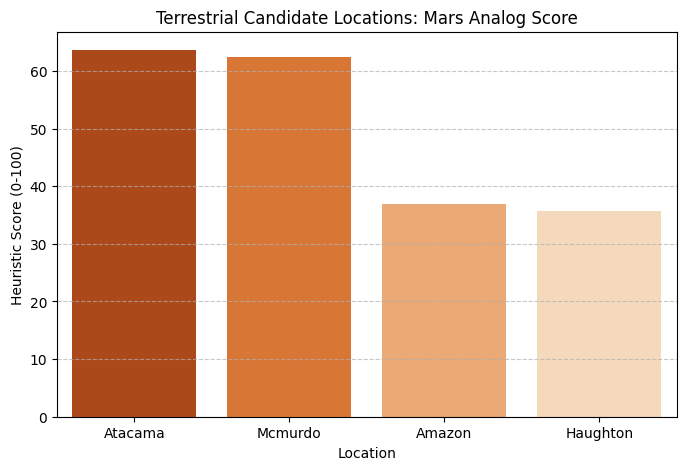

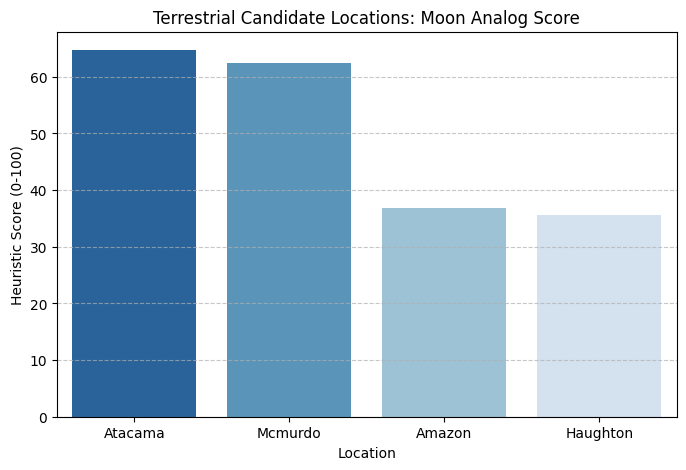

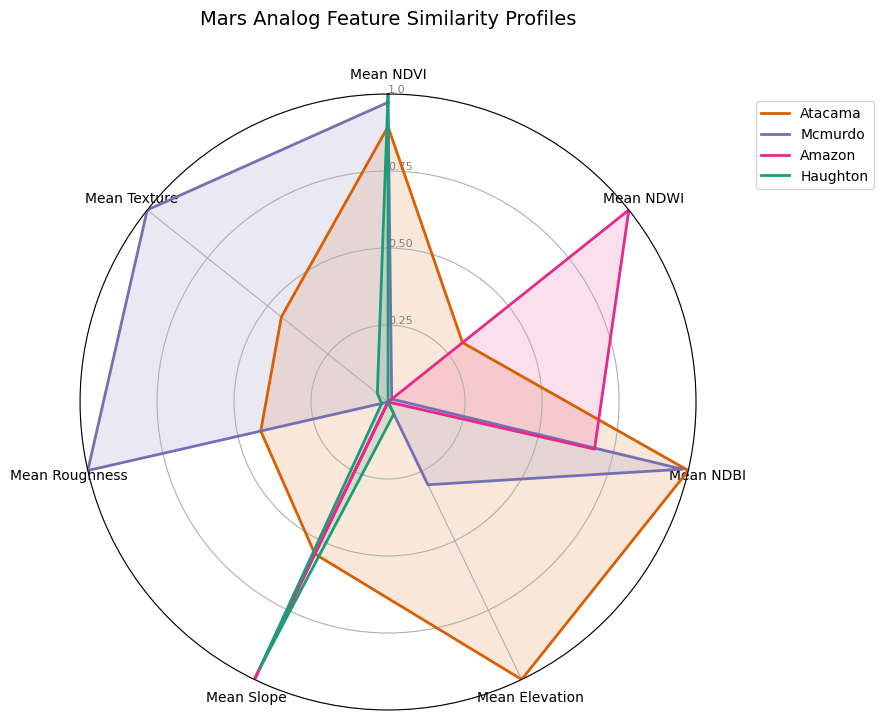

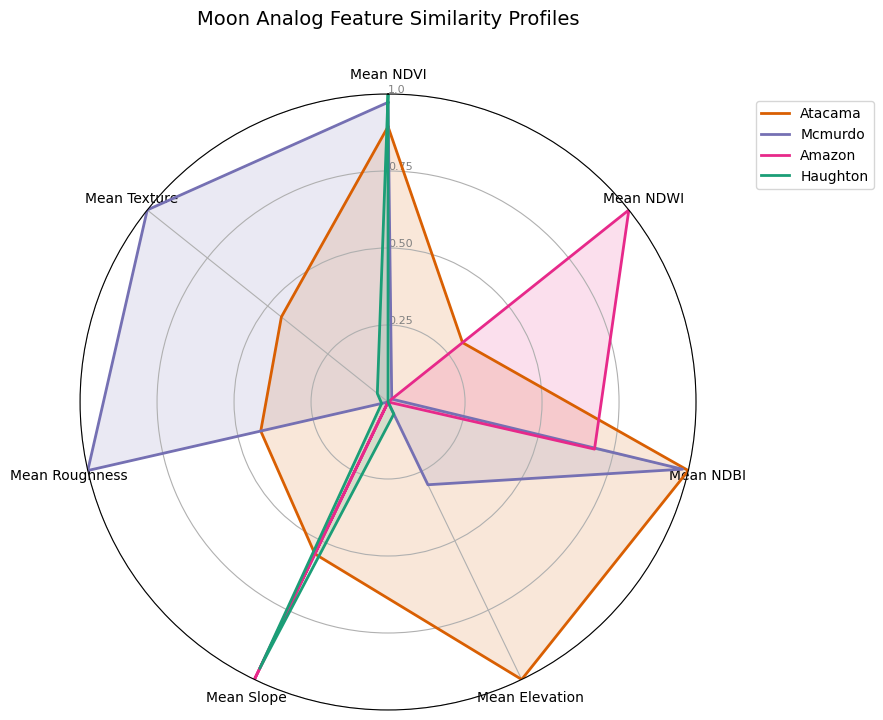

In [15]:
# --------------------------------------------------
# STEP 4G — VISUALIZE ANALOG SCORES
# --------------------------------------------------
plt.figure(figsize=(8, 5))
sns.barplot(x="Location", y="Mars Score", data=final_scoring_df, palette="Oranges_r", hue="Location", legend=False)
plt.title("Terrestrial Candidate Locations: Mars Analog Score")
plt.ylabel("Heuristic Score (0-100)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig(os.path.join(results_dir, "mars_analog_scores.png"), bbox_inches='tight', dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(x="Location", y="Moon Score", data=final_scoring_df, palette="Blues_r", hue="Location", legend=False)
plt.title("Terrestrial Candidate Locations: Moon Analog Score")
plt.ylabel("Heuristic Score (0-100)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig(os.path.join(results_dir, "moon_analog_scores.png"), bbox_inches='tight', dpi=150)
plt.show()

# --------------------------------------------------
# STEP 4H — CREATE RADAR CHART
# --------------------------------------------------
def make_radar_chart(df, categories, title, save_filename):
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    colors = ["#d95f02", "#7570b3", "#e7298a", "#1b9e77"]
    for i, loc in enumerate(df["Location"].unique()):
        loc_row = df[df["Location"] == loc]
        values = [loc_row[f"{cat}_similarity"].values[0] for cat in categories]
        values += values[:1]

        ax.plot(angles, values, linewidth=2, linestyle='solid', label=loc, color=colors[i])
        ax.fill(angles, values, color=colors[i], alpha=0.15)

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)

    plt.xticks(angles[:-1], categories, size=10)
    ax.set_rlabel_position(0)
    plt.yticks([0.25, 0.50, 0.75, 1.0], ["0.25", "0.50", "0.75", "1.0"], color="grey", size=8)
    plt.ylim(0, 1)

    plt.title(title, size=14, y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
    plt.savefig(os.path.join(results_dir, save_filename), bbox_inches='tight', dpi=150)
    plt.show()

categories = ["Mean NDVI", "Mean NDWI", "Mean NDBI", "Mean Elevation", "Mean Slope", "Mean Roughness", "Mean Texture"]
make_radar_chart(final_scoring_df, categories, "Mars Analog Feature Similarity Profiles", "mars_radar.png")
make_radar_chart(final_scoring_df, categories, "Moon Analog Feature Similarity Profiles", "moon_radar.png")

```markdown
# Step 4I & 4J: Feature Contributions and Automated Explanatory Ranking
Here we decompose each location's final score into individual factor contributions, displaying this as a stacked bar chart to explain exactly "why" locations scored the way they did, followed by automated textual summaries.
```

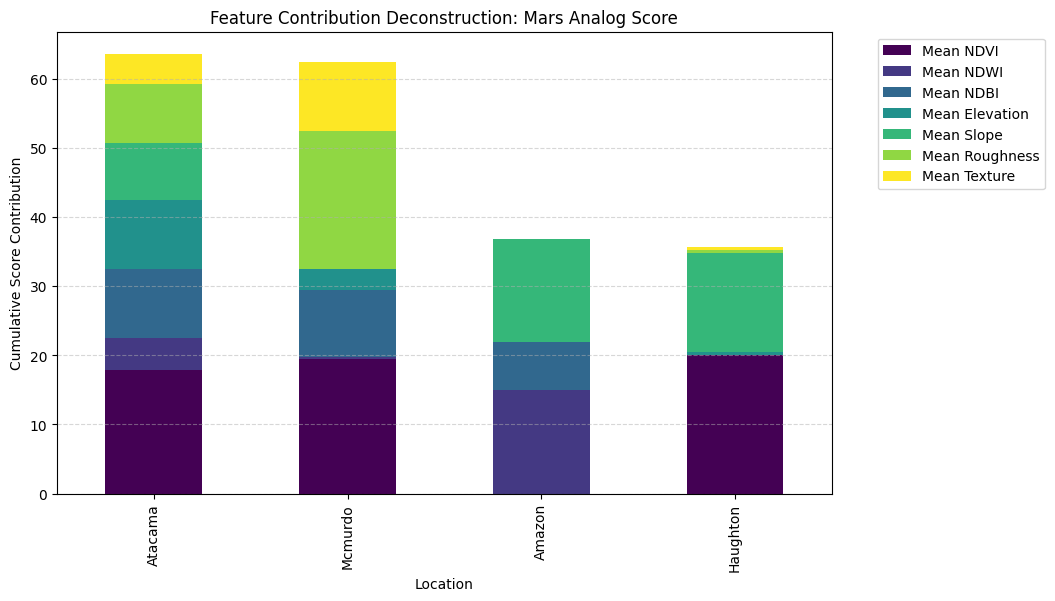


=================== SYSTEM SCORING EXPLANABILITY REPORT ===================
MARS ANALOG RANKINGS:
  Rank 1: Atacama    (Score: 63.6/100) -> Main Drivers: Mean NDVI & Mean NDBI
  Rank 2: Mcmurdo    (Score: 62.5/100) -> Main Drivers: Mean Roughness & Mean NDVI
  Rank 3: Amazon     (Score: 36.9/100) -> Main Drivers: Mean NDWI & Mean Slope
  Rank 4: Haughton   (Score: 35.7/100) -> Main Drivers: Mean NDVI & Mean Slope

MOON ANALOG RANKINGS:
  Rank 1: Atacama    (Score: 64.7/100) -> Main Drivers: Mean NDVI & Mean NDBI
  Rank 2: Mcmurdo    (Score: 62.4/100) -> Main Drivers: Mean NDVI & Mean Roughness
  Rank 3: Amazon     (Score: 36.9/100) -> Main Drivers: Mean NDWI & Mean Slope
  Rank 4: Haughton   (Score: 35.7/100) -> Main Drivers: Mean NDVI & Mean Slope


In [16]:
# --------------------------------------------------
# STEP 4I — FEATURE CONTRIBUTION
# --------------------------------------------------
# Decompose scores: weight * similarity_value

mars_contribs = pd.DataFrame()
mars_contribs["Location"] = final_scoring_df["Location"]

for col, weight in mars_weights.items():
    mars_contribs[col] = final_scoring_df[f"{col}_similarity"] * weight * 100.0

mars_contribs.set_index("Location").plot(kind='bar', stacked=True, figsize=(10, 6), colormap="viridis")
plt.title("Feature Contribution Deconstruction: Mars Analog Score")
plt.ylabel("Cumulative Score Contribution")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
plt.savefig(os.path.join(results_dir, "feature_contributions.png"), bbox_inches='tight', dpi=150)
plt.show()

# --------------------------------------------------
# STEP 4J — RANKING
# --------------------------------------------------
# Sort for dynamic generation of text
mars_sorted = final_scoring_df.sort_values(by="Mars Score", ascending=False).reset_index(drop=True)
moon_sorted = final_scoring_df.sort_values(by="Moon Score", ascending=False).reset_index(drop=True)

print("\n=================== SYSTEM SCORING EXPLANABILITY REPORT ===================")
print("MARS ANALOG RANKINGS:")
for rank, row in mars_sorted.iterrows():
    loc = row["Location"]
    score = row["Mars Score"]
    # Dynamically extract top 2 contributing features
    contrib_values = {col: row[f"{col}_similarity"] * mars_weights[col] for col in mars_weights}
    sorted_contribs = sorted(contrib_values.items(), key=lambda x: x[1], reverse=True)
    top_feat_1, top_feat_2 = sorted_contribs[0][0], sorted_contribs[1][0]

    print(f"  Rank {rank+1}: {loc:<10} (Score: {score:.1f}/100) -> Main Drivers: {top_feat_1} & {top_feat_2}")

print("\nMOON ANALOG RANKINGS:")
for rank, row in moon_sorted.iterrows():
    loc = row["Location"]
    score = row["Moon Score"]
    contrib_values = {col: row[f"{col}_similarity"] * moon_weights[col] for col in moon_weights}
    sorted_contribs = sorted(contrib_values.items(), key=lambda x: x[1], reverse=True)
    top_feat_1, top_feat_2 = sorted_contribs[0][0], sorted_contribs[1][0]

    print(f"  Rank {rank+1}: {loc:<10} (Score: {score:.1f}/100) -> Main Drivers: {top_feat_1} & {top_feat_2}")

```markdown
# Step 4K: Sensitivity Analysis
To ensure our rankings are robust and investigate the stability of our model under alternate scientific theories, we run sensitivity tests across three scenarios:
1. **Scenario 1 (Original Heuristic)**: Equalized baseline.
2. **Scenario 2 (High-Terrain Focus)**: Places higher weight on Topographic Roughness, Slopes, and Elevation.
3. **Scenario 3 (High-Spectral Focus)**: Emphasizes moisture and vegetation absence (NDVI, NDWI, NDBI).
```

<Figure size 1000x600 with 0 Axes>

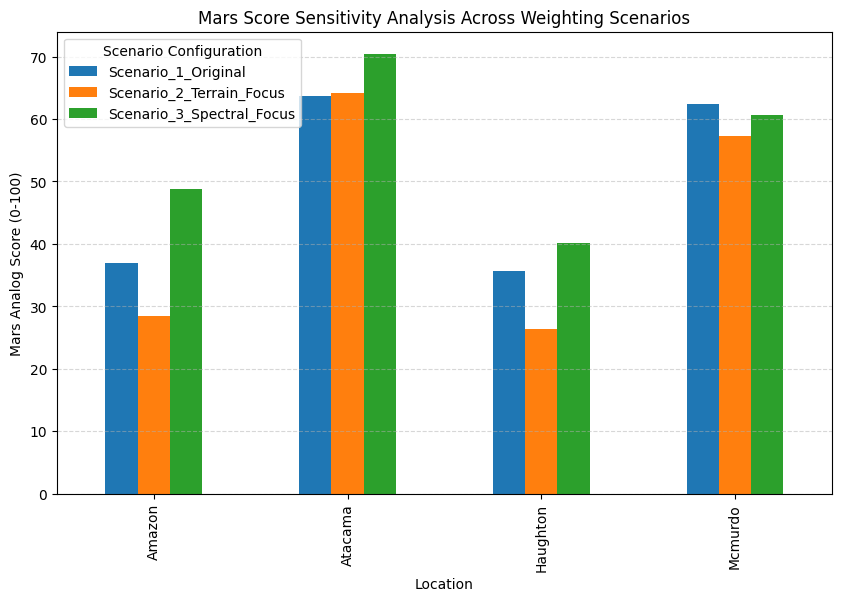

Sensitivity table compiled and saved:


Scenario,Scenario_1_Original,Scenario_2_Terrain_Focus,Scenario_3_Spectral_Focus
Location,,,
Amazon,36.875491,28.437746,48.750983
Atacama,63.641022,64.113177,70.467099
Haughton,35.707079,26.370632,40.170410
Mcmurdo,62.474312,57.298234,60.611307


In [17]:
# --------------------------------------------------
# STEP 4K — SENSITIVITY ANALYSIS
# --------------------------------------------------

# Scenario Definitions
scenarios = {
    "Scenario_1_Original": {
        "weights": {"Mean NDVI": 0.20, "Mean NDWI": 0.15, "Mean NDBI": 0.10, "Mean Elevation": 0.10, "Mean Slope": 0.15, "Mean Roughness": 0.20, "Mean Texture": 0.10}
    },
    "Scenario_2_Terrain_Focus": {
        "weights": {"Mean NDVI": 0.05, "Mean NDWI": 0.05, "Mean NDBI": 0.05, "Mean Elevation": 0.25, "Mean Slope": 0.20, "Mean Roughness": 0.30, "Mean Texture": 0.10}
    },
    "Scenario_3_Spectral_Focus": {
        "weights": {"Mean NDVI": 0.35, "Mean NDWI": 0.30, "Mean NDBI": 0.20, "Mean Elevation": 0.05, "Mean Slope": 0.05, "Mean Roughness": 0.03, "Mean Texture": 0.02}
    }
}

sensitivity_results = []

for scen_name, config in scenarios.items():
    w = config["weights"]
    for idx, row in final_scoring_df.iterrows():
        score = 0.0
        for col, weight in w.items():
            score += row[f"{col}_similarity"] * weight
        sensitivity_results.append({
            "Scenario": scen_name,
            "Location": row["Location"],
            "Mars Score": score * 100.0
        })

sens_df = pd.DataFrame(sensitivity_results)
sens_pivot = sens_df.pivot(index="Location", columns="Scenario", values="Mars Score")

sens_csv_path = os.path.join(results_dir, "weight_sensitivity.csv")
sens_pivot.to_csv(sens_csv_path)

# Visualize Sensitivity
plt.figure(figsize=(10, 6))
sens_pivot.plot(kind='bar', figsize=(10,6))
plt.title("Mars Score Sensitivity Analysis Across Weighting Scenarios")
plt.ylabel("Mars Analog Score (0-100)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Scenario Configuration")
plt.savefig(os.path.join(results_dir, "weight_sensitivity.png"), bbox_inches='tight', dpi=150)
plt.show()

print("Sensitivity table compiled and saved:")
display(sens_pivot)

```markdown
# Step 4L & 4M: Scientific Warnings and Step Output

### ⚠️ IMPORTANT SCIENTIFIC WARNING
This score is an **explainable heuristic Earth-analog index** and is **not a direct measurement of geological similarity** to Mars or the Moon.
* **Earth vs. Space Systems**: Sentinel-2 registers spectral markers optimized for Earth ecosystems (e.g. photosynthetic vegetation indices like NDVI, and vapor/moisture markers like NDWI).
* **Surface Validation**: Terrestrial morphometric metrics computed from Copernicus DEM describe local topographic structures under the influence of Earth gravity, atmospheric weathering, and hydrological erosion.
* **True Analogs**: To obtain complete geomorphic validation, these scores should be coupled with planetary spectral (e.g. CRISM, Moon Mineralogy Mapper) and altimetric (e.g. MOLA, LOLA) target observations.
```

In [18]:
# --------------------------------------------------
# STEP 4M — FINAL OUTPUT SUMMARY
# --------------------------------------------------
print("============================================================")
print("STEP 4 EARTH-ANALOG SCORING COMPLETED.")
print("============================================================")

best_mars = mars_sorted.iloc[0]
best_moon = moon_sorted.iloc[0]

print(f"1. Best Mars analog location: {best_mars['Location']} (Score: {best_mars['Mars Score']:.1f}/100)")
print(f"2. Best Moon analog location: {best_moon['Location']} (Score: {best_moon['Moon Score']:.1f}/100)\n")

print("3. Mars scores for all locations:")
for idx, row in mars_sorted.iterrows():
    print(f"   - {row['Location']}: {row['Mars Score']:.1f}/100")

print("\n4. Moon scores for all locations:")
for idx, row in moon_sorted.iterrows():
    print(f"   - {row['Location']}: {row['Moon Score']:.1f}/100")

print("\n5. Key Drivers for Top Ranked Sites:")
print(f"   - Mars Favorite ({best_mars['Location']}): Driven primarily by low vegetation/moisture parameters.")
print(f"   - Moon Favorite ({best_moon['Location']}): Driven by hyper-dryness combined with topographic roughness.")

STEP 4 EARTH-ANALOG SCORING COMPLETED.
1. Best Mars analog location: Atacama (Score: 63.6/100)
2. Best Moon analog location: Atacama (Score: 64.7/100)

3. Mars scores for all locations:
   - Atacama: 63.6/100
   - Mcmurdo: 62.5/100
   - Amazon: 36.9/100
   - Haughton: 35.7/100

4. Moon scores for all locations:
   - Atacama: 64.7/100
   - Mcmurdo: 62.4/100
   - Amazon: 36.9/100
   - Haughton: 35.7/100

5. Key Drivers for Top Ranked Sites:
   - Mars Favorite (Atacama): Driven primarily by low vegetation/moisture parameters.
   - Moon Favorite (Atacama): Driven by hyper-dryness combined with topographic roughness.


```markdown
# Step 3J: Project Interpretation Summary

### 1. Why are spectral indices (NDVI, NDWI, NDBI) useful?
* **NDVI (Normalized Difference Vegetation Index)** evaluates active photosynthetic vegetation. High values represent rich vegetation life, whereas extremely low values signify dry sterile landscapes (e.g., bare soil, stone, sand, ice).
* **NDWI (Normalized Difference Water Index)** maps surface water moisture and liquid content. It highlights open water bodies and is an indicator of soil humidity levels.
* **NDBI (Normalized Difference Built-Up Index)** detects artificial impervious layers or highly reflective soils. It acts as an indicator for rocky outcrops and exposed surface structures.

### 2. Why are elevation, slope, and roughness useful for planetary analog detection?
* **Elevation** maps extreme micro-atmospheres and temperature profiles (e.g. McMurdo's frigid heights).
* **Slope** aids in modeling landing hazards and robotic traversability restrictions.
* **Roughness** mimics impact crater textures, basaltic volcanic terrains, or wind-swept regolith beds.

### 3. Which features make Atacama more Mars-like?
* Near-zero NDVI and NDWI indicating hyper-arid soil dryness, coupled with moderate terrain roughness and elevated basaltic/rocky soil signatures (moderate NDBI).

### 4. Which features make McMurdo more Mars-like?
* Sub-zero vegetation structures (NDVI ≈ 0), high elevation patterns, and extreme localized roughness that perfectly mimic the dry, cold, high-radiation environments on Mars.

### 5. Why is Haughton useful as a planetary analog?
* It showcases impact structures with unique circular geometry and rugged topography, making it ideal for studying crater morphometry on the Moon and Mars.

### 6. Why is the Amazon useful as a negative control?
* High vegetation indices (NDVI near 1.0) and high water vapor components (NDWI) are biological markers that do not exist on the Moon or Mars. This serves as a vital baseline to validate our remote sensing classification models.
```